# TD6 — Exercice 1 : Variogramme 1D du prix de l'or

**Traitement statistique, géostatistique et approche systèmes — ENSG 2A (S7)**

*Auteurs: Guillaume Caumon, Oumayma Razik*

On se propose d'étudier les statistiques et la variabilité temporelle du cours de l'or (variable **`GoldPrice`**), en dollars par once ($/once)** du 01/01/1982 au 09/10/1997 (4 174 valeurs). L'objectif est de cartactériser la volatilité, c'est à dire la vitesse et la fréquence auxquelle le cours de cette "valeur refuge" tend à évoluer sur la période.

Nous allons commencer par étudier la série temporellle et sa distribution avant de calculer le variogramme expérimental.

## 1. Chargement et visualisation des données

On charge le fichier `prix_or_1D.csv` contenant les 4 174 valeurs du prix de l'or.
Avant d'étudier la distribution statistique, on commence par charger et vérifier les données.

In [1]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gstlearn as gl
import gstlearn.plot as gp
import ipywidgets as widgets
from ipywidgets import interactive_output

# Ajout du chemin d'importation pour le module geostat_utils 
sys.path.append(os.path.abspath(os.path.join("..")))
import geostat_utils as gsutils

# Set output directory for figures
results = gsutils.ResultsDir("/TD6_outputs")

# Load the data and set the data as index to make date-based queries easy
gold_price = pd.read_csv('../data/prix_or_1D.csv', header=0)
gold_price["Date"] = pd.to_datetime(gold_price["Date"], dayfirst=True)
gold_price.set_index("Date", inplace=True)
print(gold_price)

            Days   GoldPrice
Date                        
1982-01-01     0  397.500000
1982-01-04     3  395.000000
1982-01-05     4  403.500000
1982-01-06     5  401.500000
1982-01-07     6  396.500000
...          ...         ...
1997-10-03  5754  292.500000
1997-10-04  5755  292.500000
1997-10-07  5758  293.049988
1997-10-08  5759  290.200012
1997-10-09  5760  290.200012

[4174 rows x 2 columns]


Regardons à présent l'histogramme:

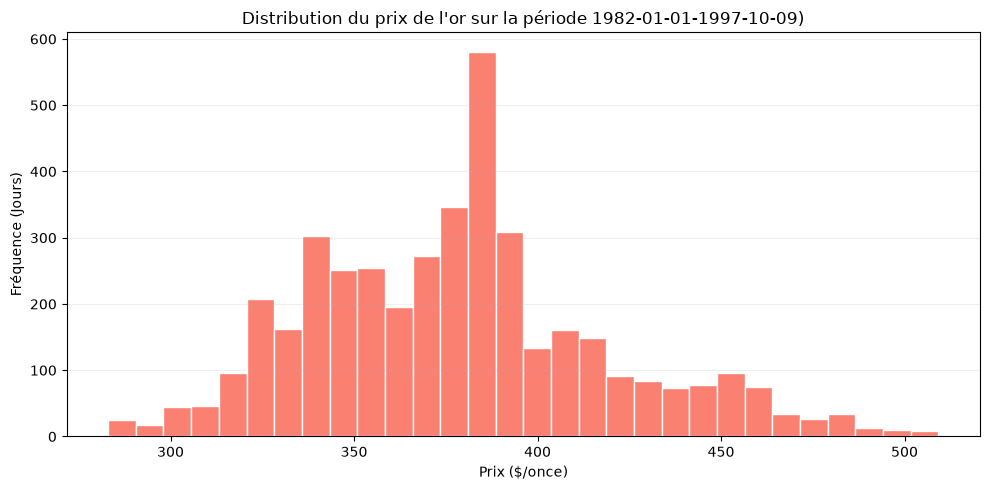

In [2]:
def plot_gold_histogram(df: pd.DataFrame, start_date: str = None, end_date: str = None):
    plt.figure(figsize=(10, 5))
    # edge color helps separate the bars visually
    plt.hist(df["GoldPrice"], bins=30, color="salmon", edgecolor="white")
    actual_start = start_date if start_date else df.index.min().strftime('%Y-%m-%d')
    actual_end = end_date if end_date else df.index.max().strftime('%Y-%m-%d')

    plt.title(f"Distribution du prix de l'or sur la période {actual_start}-{actual_end})")
    plt.xlabel("Prix ($/once)")
    plt.ylabel("Fréquence (Jours)")
    plt.grid(axis='y', alpha=0.2)
    plt.tight_layout()
    results.save_fig('01_Histogramme_Prix_Or.png', bbox_inches='tight')
    plt.show()

plot_gold_histogram(gold_price)
# gold_price["GoldPrice"].plot(color='salmon', linewidth=1, figsize=(12, 4))


Comme la période d'observation est longue, nous allons travailler sur une pédiode limitée pour avoir un calcul quasi-instantanné. Mettons-nous dans la peau d'un spéculateur des années 1980, et considérons les données entre Juillet 1982 et Février 1983 pour calculer notre premier variogramme.

In [3]:
# Slice data [You can change the start and end dates]
start_date = "1982-07-01"
end_date = "1983-02-15"

elapsed = pd.to_datetime(end_date) - pd.to_datetime(start_date)
print(f"La durée de la période considérée est de {elapsed.days} jours")

gold_price_sliced = gold_price.loc[start_date:end_date]

La durée de la période considérée est de 229 jours


Nous pouvons maintenant choisir les paramètres de calcul du variogramme: le nombre d'intervalles (`nlags`), la taille de chaque intervalle (`dlag`) et la tolérance (`toldis`).

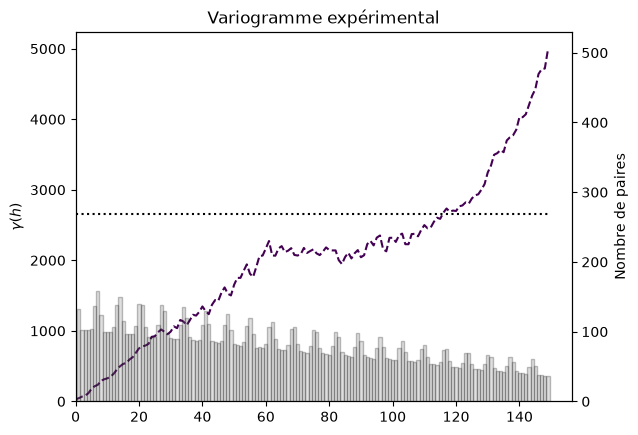

In [5]:
# Variogram computation parameters [You need to define them!]
number_of_lags = 115
lag_size = 1
params_vario_prix_or = gl.VarioParam.createOmniDirection(
    nlag=150,
    dlag=1,
    toldis=0.5
)

# Create the gstlearn 1D database
gl.defineDefaultSpace(gl.ESpaceType.RN, 1)
gl_data = gl.Db_fromPandas(gold_price_sliced)
gl_data.setLocator("Days", gl.ELoc.X)  # 1D coordinate
gl_data.setLocator("GoldPrice", gl.ELoc.Z)  # Variable of interest

variogram_gold = gl.Vario.computeFromDb(
    varioparam=params_vario_prix_or,
    db=gl_data
)

gsutils.plot_1D_variogram(variogram_gold)

Pour vérifier, Considérons la période 1982-1984, pour calculer notre premier variogramme.

et affichons la série temporelle.

**Cette série peut-elle être considérée comme stationnaire ?**

In [ ]:


# We can now plot the gold price data for the selected period
gold_price_sliced["GoldPrice"].plot(color='salmon', linewidth=1, figsize=(12, 4))

# plt.figure(figsize=(12, 4))
# plt.plot(gold_price_sliced["Date"], gold_price_sliced["GoldPrice"], color='salmon', linewidth=1)
# plt.title("Prix de l'or de 1982 à 1997")
# plt.xlabel("Date")
# plt.ylabel("Prix ($/once)")
# # plt.grid(alpha=0.3)
# plt.tight_layout()
# plt.savefig(f"{output_dir}/01_Serie_Prix_Or.png", bbox_inches="tight")
# plt.show()

## 3. Histogramme et courbe cumulative

In [ ]:
#----calcul histogramme du GoldPrice----

gp_valeurs = data_prix_or['GoldPrice']
plt.figure (figsize=(7, 4))
plt.hist(gp_valeurs, bins=50, weights = np.ones(len(gp_valeurs))/len(gp_valeurs),
          color ='salmon' , edgecolor='white')
plt.title("Histogramme du GoldPrice ($/once)")
plt.xlabel("GoldPrice ($/once)")
plt.ylabel("Proportion")
plt.tight_layout()
plt.savefig(f"{DOSSIER_SORTIE}/ex1_histogramme.png", dpi=150, bbox_inches="tight")
plt.show()

#----------Statistques du GoldPrice--------

nombre_mesures=len(gp_valeurs)
min_value = np.min(gp_valeurs)
max_value = np.max(gp_valeurs)
moyenne_gp = np.mean(gp_valeurs)
mediane_gp = np.median(gp_valeurs)
premier_quartile = np.percentile(gp_valeurs,25)
troisieme_quartile = np.percentile(gp_valeurs,75)
IQR= troisieme_quartile-premier_quartile
ecart_type_gp = np.std(gp_valeurs, ddof=1)
variance_gp = np.var(gp_valeurs, ddof=1)
gold_trie = np.sort(gp_valeurs)
gp_cumulative = np.arange (1,len(gold_trie)+1)/len(gold_trie)

#----------Distribution cumulative(GoldPrice)-------- 

plt.figure(figsize=(7,4))
plt.plot(gold_trie, gp_cumulative, color='salmon' ,linewidth=2 , label='GoldPrice')
plt.title("Distribution cumulative du GoldPrice ($/once)")
plt.xlabel("GoldPrice ($/once)")
plt.ylabel("Proportion cumulée")
plt.legend(loc='lower right')

# ---- Statistiques sur le graphe ----
text_stats = (
    f"N = {nombre_mesures}\n"
    f"Min = {min_value:.2f}\n"
    f"Max = {max_value:.2f}\n"
    f"Moyenne = {moyenne_gp:.2f}\n"
    f"Médiane = {mediane_gp:.2f}\n"
    f"Q1 = {premier_quartile:.2f}\n"
    f"Q3 = {troisieme_quartile:.2f}\n"
    f"IQR = {IQR:.2f}\n"
    f"Écart-type = {ecart_type_gp:.2f}\n"
    f"Variance = {variance_gp:.2f}"
)
plt.text(0.74, 0.35,
    text_stats,
    transform=plt.gca().transAxes,
    fontsize=9,
    fontweight='bold',
    bbox=dict(facecolor='white', edgecolor='black')
)
plt.grid()
plt.tight_layout()
plt.savefig(f"{DOSSIER_SORTIE}/ex1_cumulative.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
#---- Calcul du variogramme expérimental en 1D ----
params_vario_prix_or = gl.VarioParam.createOmniDirection(
    nlag=50,
    dlag=1,
    toldis=0.5
)

vario_prix_or = gl.Vario.computeFromDb(
    varioparam=params_vario_prix_or,
    db=db_prix_or
)
print(vario_prix_or)

In [ ]:
#---- Affichage du variogramme expérimental en 1D ----
variance_prix_or = np.var(data_prix_or['GoldPrice'], ddof=1)
print(f"Variance GoldPrice = {variance_prix_or:.2f}")
ax = gp.varmod(vario_prix_or, showPairs=False)
ax.set_ylim(0, variance_prix_or * 2)
plt.xlabel("Distance (m)")
plt.ylabel(r"$\gamma(h)$")
plt.title("Variogramme expérimental 1D — GoldPrice")
plt.savefig(f"{DOSSIER_SORTIE}/ex1_variogramme_exp.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Ajustement automatique du modèle

### 6.1 Modèle Sphérique sans nugget

In [ ]:
#---- Ajustement automatique - Modèle Sphérique sans nugget ----
# Affichage factorisé via gutils.afficher_variogramme 
variance_prix_or = np.var(data_prix_or['GoldPrice'], ddof=1)
print(f"Variance GoldPrice = {variance_prix_or:.2f}")

model_sph_prix_or = gl.Model()
err = model_sph_prix_or.fit(vario_prix_or, types=[gl.ECov.SPHERICAL])
gutils.afficher_variogramme(
    vario_prix_or, model_sph_prix_or,
    "Modèle Sphérique sans nugget — GoldPrice 1D",
    variance_prix_or, unite="m",
    chemin_fichier=f"{DOSSIER_SORTIE}/ex1_modele_spherique.png"
)

### 6.2 Modèle Sphérique avec Nugget

In [ ]:
#---- Ajustement automatique - Nugget + Sphérique ----
model_nug_sph_prix_or = gl.Model()
err = model_nug_sph_prix_or.fit(vario_prix_or, types=[gl.ECov.NUGGET, gl.ECov.SPHERICAL])
gutils.afficher_variogramme(
    vario_prix_or, model_nug_sph_prix_or,
    "Ajustement automatique — Nugget + Sphérique — GoldPrice 1D",
    variance_prix_or, unite="m",
    chemin_fichier=f"{DOSSIER_SORTIE}/ex1_modele_nugget_spherique.png"
)

### 6.3 Ajustement manuel interactif

In [ ]:
calage_gold = gutils.creer_widget_calage_variogramme(
    vario_prix_or, variance_prix_or,
    valeurs_defaut={
        'Spherique':   (0.0, 1440.0),
        'Exponentiel': (0.0, 2000.0),
        'Gaussien':    (0.0, 1200.0),
    },
    facteur_correction=variance_prix_or,
    unite="m",
    portee_min=100.0,
    portee_max=3000.0,
    chemin_sortie=DOSSIER_SORTIE,
)

In [ ]:
model_final_gold = calage_gold.model
print(model_final_gold)